# Lab 3 — Text-to-Latent Representation

**Objective:** Transform customer reviews into numerical representations using preprocessing, tokenization, padding, learned word embeddings, flattening, and PCA.

## Additional learning included in this notebook

- **Transparent preprocessing:** lowercasing, punctuation handling, whitespace normalization, and token-count inspection.
- **Reproducible vocabulary:** deterministic token IDs with an explicit `<PAD>` token and an explanation that IDs are lookup keys, not measurements.
- **Shape tracing:** dimensions are checked from token sequences through padded IDs, embedding tensors, and flattened vectors.
- **Learned embeddings:** a seeded Keras embedding layer is trained through a small sentiment classifier; the training result is distinguished from a random initial embedding.
- **Padding semantics:** `mask_zero=True` ensures padded positions do not affect the classifier’s masked average.
- **Representation inspection:** both the per-word lookup table and each sentence’s ordered embedding matrix are displayed.
- **Flattening versus pooling:** the full sequence is flattened for the requested feature vector, while masked global average pooling is used separately for classification.
- **PCA visualization:** vocabulary-word embeddings are reduced to two dimensions and annotated.
- **Reliability checks:** assertions verify vocabulary IDs, sequence shapes, embedding lookup behavior, padding, and PCA output.
- **Limitations:** the five-example dataset is a teaching demonstration, not a statistically valid sentiment benchmark.

### Complete data flow

```text
raw reviews → normalized text → vocabulary/token IDs → post-padded sequences
→ learned embedding tensor → flattened sentence vectors → PCA word visualization
```

## Conventions and execution notes

**What:** Set up a fully reproducible, offline experiment.

**Why:** A fixed seed makes the demonstration repeatable and avoids relying on external pretrained models or downloads. The labels make it possible to demonstrate supervised embedding updates; they should not be interpreted as a real evaluation dataset.

In [1]:
import os
import random
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.decomposition import PCA
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__}")
print(f"NumPy {np.__version__} | pandas {pd.__version__}")

Python 3.14.6 | TensorFlow 2.22.0-rc0
NumPy 2.5.1 | pandas 3.0.3


## 1. Create the customer-review dataset

**What:** Store the five reviews and their demonstration sentiment labels.

**Why:** The labels provide a small supervised objective through which the embedding layer can learn values. The first three reviews are positive examples and the final two are negative examples.

In [2]:
texts = [
    "The product quality is excellent",
    "I really love this product",
    "The quality of this item is amazing",
    "The product performance is poor",
    "I dislike this product completely",
]
labels = np.array([1, 1, 1, 0, 0], dtype=np.float32)

review_df = pd.DataFrame({
    "review_id": np.arange(1, len(texts) + 1),
    "text": texts,
    "label": labels.astype(int),
    "sentiment": np.where(labels == 1, "positive", "negative"),
})
display(review_df)

,review_id,text,label,sentiment
0,1,The product quality is excellent,1,positive
1,2,I really love this product,1,positive
2,3,The quality of this item is amazing,1,positive
3,4,The product performance is poor,0,negative
4,5,I dislike this product completely,0,negative


## 2. Pre-process the reviews

**What:** Normalize case and punctuation while retaining word boundaries.

**Why:** Tokenizers should see equivalent spellings consistently; this makes the vocabulary easier to inspect and reproduce.

In [3]:
def normalize_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

cleaned_texts = [normalize_text(text) for text in texts]
preprocessing_df = pd.DataFrame({
    "original_text": texts,
    "cleaned_text": cleaned_texts,
})
preprocessing_df["token_count"] = preprocessing_df["cleaned_text"].str.split().str.len()
display(preprocessing_df)
assert all(preprocessed for preprocessed in cleaned_texts)

,original_text,cleaned_text,token_count
0,The product quality is excellent,the product quality is excellent,5
1,I really love this product,i really love this product,5
2,The quality of this item is amazing,the quality of this item is amazing,7
3,The product performance is poor,the product performance is poor,5
4,I dislike this product completely,i dislike this product completely,5


## 3. Build the vocabulary and convert text to token IDs

**What:** Fit a tokenizer and display the mapping from every unique word to its integer ID.

**Why:** Token IDs are categorical lookup keys. For example, ID 8 is not “more positive” or “larger” than ID 2; the embedding layer learns a vector for each ID.

In [4]:
tokenizer = Tokenizer(num_words=None, oov_token=None, filters="")
tokenizer.fit_on_texts(cleaned_texts)
word_index = tokenizer.word_index

vocab_table = pd.DataFrame(
    [{"token": "<PAD>", "token_id": 0}]
    + [
        {"token": word, "token_id": token_id}
        for word, token_id in sorted(word_index.items(), key=lambda item: item[1])
    ]
)
display(vocab_table)
assert vocab_table["token_id"].is_unique
assert set(vocab_table["token_id"]) == set(range(len(word_index) + 1))

sequences = tokenizer.texts_to_sequences(cleaned_texts)
sequence_df = pd.DataFrame({
    "review_id": np.arange(1, len(texts) + 1),
    "cleaned_text": cleaned_texts,
    "token_sequence": sequences,
})
display(sequence_df)
assert all(len(sequence) == len(text.split()) for sequence, text in zip(sequences, cleaned_texts))

,token,token_id
0,<PAD>,0
1,product,1
2,the,2
3,is,3
4,this,4
5,quality,5
6,i,6
7,excellent,7
8,really,8
9,love,9


,review_id,cleaned_text,token_sequence
0,1,the product quality is excellent,"[2, 1, 5, 3, 7]"
1,2,i really love this product,"[6, 8, 9, 4, 1]"
2,3,the quality of this item is amazing,"[2, 5, 10, 4, 11, 3, 12]"
3,4,the product performance is poor,"[2, 1, 13, 3, 14]"
4,5,i dislike this product completely,"[6, 15, 4, 1, 16]"


## 4. Pad all token sequences to a common length

**What:** Derive the longest review length and post-pad shorter sequences with ID `0`.

**Why:** Neural networks process a uniform tensor. Post-padding keeps the original word order at the beginning of every row and makes the padding positions easy to identify.

In [5]:
max_length = max(map(len, sequences))
padded_sequences = pad_sequences(
    sequences, maxlen=max_length, padding="post", truncating="post", value=0
)

padded_df = pd.DataFrame(
    padded_sequences,
    index=[f"review_{review_id}" for review_id in review_df["review_id"]],
    columns=[f"position_{i + 1}" for i in range(max_length)],
)
display(padded_df)
print(f"Padded tensor shape: {padded_sequences.shape}")
assert padded_sequences.shape == (len(texts), max_length)
assert np.all(padded_sequences >= 0)
assert all(
    np.all(row[length:] == 0)
    for row, length in zip(padded_sequences, map(len, sequences))
    if length < max_length
)  # shorter examples end with padding

,position_1,position_2,position_3,position_4,position_5,position_6,position_7
review_1,2,1,5,3,7,0,0
review_2,6,8,9,4,1,0,0
review_3,2,5,10,4,11,3,12
review_4,2,1,13,3,14,0,0
review_5,6,15,4,1,16,0,0


Padded tensor shape: (5, 7)


## 5. Train a small model with a learnable embedding layer

**What:** Map each token ID to an eight-dimensional vector and train those vectors through a masked global-average sentiment classifier.

**Why:** An embedding layer replaces sparse integer IDs with dense values that can be optimized from data. `mask_zero=True` prevents padding from influencing the classifier, while the complete embedding sequence remains available for inspection and flattening.

In [6]:
vocab_size = len(word_index) + 1
embedding_dimension = 8

inputs = layers.Input(shape=(max_length,), dtype="int32", name="token_ids")
embedding_layer = layers.Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dimension,
    mask_zero=True,
    name="word_embedding",
)
embedded = embedding_layer(inputs)
pooled = layers.GlobalAveragePooling1D(name="masked_average")(embedded)
outputs = layers.Dense(1, activation="sigmoid", name="sentiment_output")(pooled)
embedding_model = Model(inputs, outputs, name="review_embedding_classifier")
embedding_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.03),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
embedding_model.summary()

Model: "review_embedding_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 7, 8)      │        136 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 7)         │          0 │ token_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masked_average      │ (None, 8)         │          0 │ word_embedding[0… │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment_output    │ (None, 1)         │          9 │ masked_average[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)

,accuracy,loss
145,1.0,0.000877
146,1.0,0.000869
147,1.0,0.000861
148,1.0,0.000853
149,1.0,0.000846


,accuracy,loss
0,1.0,0.000838


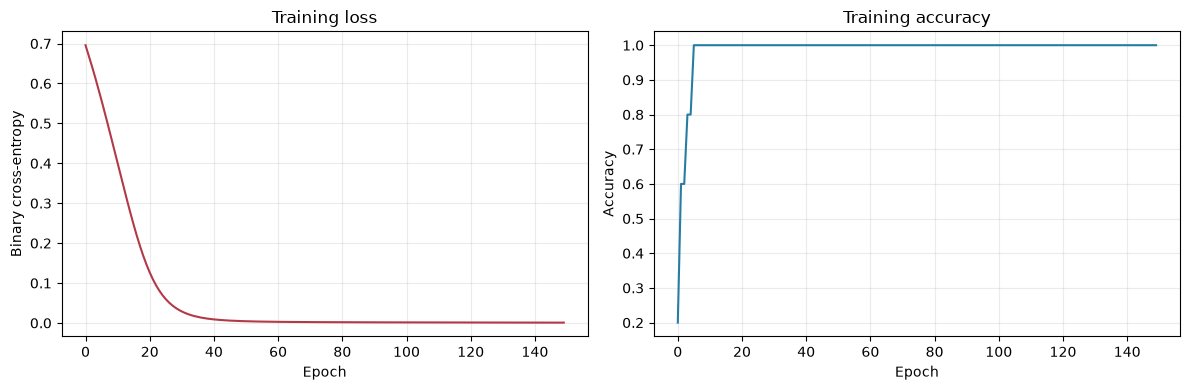

In [7]:
history = embedding_model.fit(
    padded_sequences,
    labels,
    epochs=150,
    batch_size=len(texts),
    shuffle=False,
    verbose=0,
)
training_metrics = embedding_model.evaluate(
    padded_sequences, labels, verbose=0, return_dict=True
)

display(pd.DataFrame(history.history).tail())
display(pd.DataFrame([training_metrics]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], color="#b23a48")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[1].plot(history.history["accuracy"], color="#277da1")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Important interpretation

The model is trained on only five examples with no held-out test set. Its training curve demonstrates the update mechanism, not generalization performance. The initial vectors are random; the final vectors are the learned weights after the binary sentiment objective. Keras uses ID `0` as a mask; the exported sentence matrices additionally make those padded positions explicit zero vectors.

## 6. Inspect the learned word embeddings

**What:** Extract the embedding matrix, the per-sentence embedding tensor, and a readable word-to-vector table.

**Why:** Every non-padding token ID selects one row from the embedding matrix. A sentence therefore becomes an ordered matrix of vectors with shape `(number of positions, embedding dimension)`.

In [8]:
embedding_extractor = Model(inputs, embedded, name="embedding_extractor")
embedding_tensor = embedding_extractor.predict(padded_sequences, verbose=0)
embedding_matrix = embedding_layer.get_weights()[0]
sentence_embeddings = embedding_tensor.reshape(
    len(texts), max_length, embedding_dimension
)
# Export padding as a zero vector while preserving Keras' masking behavior.
padding_mask = padded_sequences[..., np.newaxis] == 0
sentence_embeddings = np.where(padding_mask, 0.0, sentence_embeddings)

print(f"Embedding tensor shape: {embedding_tensor.shape}")
print(f"Vocabulary embedding matrix shape: {embedding_matrix.shape}")
assert embedding_tensor.shape == (len(texts), max_length, embedding_dimension)
assert np.allclose(sentence_embeddings[padded_sequences == 0], 0.0)
assert embedding_matrix.shape == (vocab_size, embedding_dimension)
print("Padding is excluded from masked pooling and exported as a zero vector.")

first_non_padding_id = int(padded_sequences[0, 0])
assert np.allclose(embedding_tensor[0, 0], embedding_matrix[first_non_padding_id])
print(f"Lookup check passed: token ID {first_non_padding_id} selects one {embedding_dimension}D vector.")

words = [word for word, _ in sorted(word_index.items(), key=lambda item: item[1])]
word_vectors = pd.DataFrame(
    embedding_matrix[1:],
    index=words,
    columns=[f"dim_{i + 1}" for i in range(embedding_dimension)],
)
word_vectors.index.name = "word"
display(word_vectors.round(4))

Embedding tensor shape: (5, 7, 8)
Vocabulary embedding matrix shape: (17, 8)
Padding is excluded from masked pooling and exported as a zero vector.
Lookup check passed: token ID 2 selects one 8D vector.


,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8
word,,,,,,,,
product,-0.2493,0.3352,-0.3089,-0.2747,-0.2156,0.2543,-0.2739,-0.2853
the,0.0136,0.0034,0.0502,0.0033,0.0078,-0.0224,0.0856,-0.0220
is,0.0976,-0.0031,0.0450,0.0529,0.0607,-0.0872,0.0150,0.0506
this,0.1610,-0.2134,0.1844,0.1727,0.2268,-0.2348,0.2263,0.2316
quality,1.2927,-1.9250,1.4421,1.4721,1.4529,-1.3897,1.4992,1.7899
i,-0.1419,0.1246,-0.0933,-0.1029,-0.1532,0.0664,-0.0781,-0.0722
excellent,1.0590,-1.5981,1.1261,1.1501,1.1515,-1.0710,1.1904,1.4959
really,1.1516,-1.5864,1.2599,1.2950,1.2654,-1.1767,1.3237,1.5800
love,1.2052,-1.6417,1.2919,1.2617,1.2753,-1.1876,1.3112,1.5090


In [9]:
for review_id, text, token_ids, matrix in zip(
    review_df["review_id"], texts, padded_sequences, sentence_embeddings
):
    print(f"Review {review_id}: {text}")
    display(pd.DataFrame(
        matrix,
        index=[f"position_{i + 1} (ID {token_id})" for i, token_id in enumerate(token_ids)],
        columns=[f"dim_{i + 1}" for i in range(embedding_dimension)],
    ).round(4))

Review 1: The product quality is excellent


,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8
position_1 (ID 2),0.0136,0.0034,0.0502,0.0033,0.0078,-0.0224,0.0856,-0.0220
position_2 (ID 1),-0.2493,0.3352,-0.3089,-0.2747,-0.2156,0.2543,-0.2739,-0.2853
position_3 (ID 5),1.2927,-1.9250,1.4421,1.4721,1.4529,-1.3897,1.4992,1.7899
position_4 (ID 3),0.0976,-0.0031,0.0450,0.0529,0.0607,-0.0872,0.0150,0.0506
position_5 (ID 7),1.0590,-1.5981,1.1261,1.1501,1.1515,-1.0710,1.1904,1.4959
position_6 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
position_7 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Review 2: I really love this product


,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8
position_1 (ID 6),-0.1419,0.1246,-0.0933,-0.1029,-0.1532,0.0664,-0.0781,-0.0722
position_2 (ID 8),1.1516,-1.5864,1.2599,1.2950,1.2654,-1.1767,1.3237,1.5800
position_3 (ID 9),1.2052,-1.6417,1.2919,1.2617,1.2753,-1.1876,1.3112,1.5090
position_4 (ID 4),0.1610,-0.2134,0.1844,0.1727,0.2268,-0.2348,0.2263,0.2316
position_5 (ID 1),-0.2493,0.3352,-0.3089,-0.2747,-0.2156,0.2543,-0.2739,-0.2853
position_6 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
position_7 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Review 3: The quality of this item is amazing


,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8
position_1 (ID 2),0.0136,0.0034,0.0502,0.0033,0.0078,-0.0224,0.0856,-0.0220
position_2 (ID 5),1.2927,-1.9250,1.4421,1.4721,1.4529,-1.3897,1.4992,1.7899
position_3 (ID 10),0.7797,-1.0686,0.8198,0.8551,0.8178,-0.8629,0.9236,1.0893
position_4 (ID 4),0.1610,-0.2134,0.1844,0.1727,0.2268,-0.2348,0.2263,0.2316
position_5 (ID 11),0.8225,-1.1123,0.8693,0.8950,0.8423,-0.8655,0.9272,1.0425
position_6 (ID 3),0.0976,-0.0031,0.0450,0.0529,0.0607,-0.0872,0.0150,0.0506
position_7 (ID 12),0.8402,-1.0802,0.8529,0.8297,0.8895,-0.7957,0.8935,1.0246


Review 4: The product performance is poor


,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8
position_1 (ID 2),0.0136,0.0034,0.0502,0.0033,0.0078,-0.0224,0.0856,-0.0220
position_2 (ID 1),-0.2493,0.3352,-0.3089,-0.2747,-0.2156,0.2543,-0.2739,-0.2853
position_3 (ID 13),-1.1346,1.3913,-1.2209,-1.2062,-1.1034,1.1266,-1.2206,-1.3126
position_4 (ID 3),0.0976,-0.0031,0.0450,0.0529,0.0607,-0.0872,0.0150,0.0506
position_5 (ID 14),-1.1077,1.4045,-1.1786,-1.2107,-1.0997,1.0912,-1.2235,-1.3495
position_6 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
position_7 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Review 5: I dislike this product completely


,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8
position_1 (ID 6),-0.1419,0.1246,-0.0933,-0.1029,-0.1532,0.0664,-0.0781,-0.0722
position_2 (ID 15),-1.0990,1.3647,-1.2227,-1.1539,-1.1034,1.1082,-1.1579,-1.3931
position_3 (ID 4),0.1610,-0.2134,0.1844,0.1727,0.2268,-0.2348,0.2263,0.2316
position_4 (ID 1),-0.2493,0.3352,-0.3089,-0.2747,-0.2156,0.2543,-0.2739,-0.2853
position_5 (ID 16),-1.0885,1.3743,-1.1504,-1.2197,-1.1303,1.1382,-1.2151,-1.3983
position_6 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
position_7 (ID 0),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 7. Flatten each sentence embedding matrix

**What:** Convert each `(max_length, embedding_dimension)` matrix into one row vector.

**Why:** Flattening preserves the order of positions and all embedding coordinates, producing a fixed-length feature vector suitable for a downstream model. It is different from masked average pooling: flattening retains positional detail but creates more features.

In [10]:
flattened_vectors = sentence_embeddings.reshape(len(texts), -1)
flattened_columns = [
    f"position_{position + 1}_dim_{dimension + 1}"
    for position in range(max_length)
    for dimension in range(embedding_dimension)
]
flattened_df = pd.DataFrame(flattened_vectors, columns=flattened_columns)
flattened_df.insert(0, "review_id", review_df["review_id"].values)
display(flattened_df.round(4))
print(f"Flattened vector shape: {flattened_vectors.shape}")
assert flattened_vectors.shape == (len(texts), max_length * embedding_dimension)

,review_id,position_1_dim_1,position_1_dim_2,position_1_dim_3,position_1_dim_4,position_1_dim_5,position_1_dim_6,position_1_dim_7,position_1_dim_8,position_2_dim_1,...,position_6_dim_7,position_6_dim_8,position_7_dim_1,position_7_dim_2,position_7_dim_3,position_7_dim_4,position_7_dim_5,position_7_dim_6,position_7_dim_7,position_7_dim_8
0,1,0.0136,0.0034,0.0502,0.0033,0.0078,-0.0224,0.0856,-0.0220,-0.2493,...,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,2,-0.1419,0.1246,-0.0933,-0.1029,-0.1532,0.0664,-0.0781,-0.0722,1.1516,...,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,3,0.0136,0.0034,0.0502,0.0033,0.0078,-0.0224,0.0856,-0.0220,1.2927,...,0.015,0.0506,0.8402,-1.0802,0.8529,0.8297,0.8895,-0.7957,0.8935,1.0246
3,4,0.0136,0.0034,0.0502,0.0033,0.0078,-0.0224,0.0856,-0.0220,-0.2493,...,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,5,-0.1419,0.1246,-0.0933,-0.1029,-0.1532,0.0664,-0.0781,-0.0722,-1.0990,...,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Flattened vector shape: (5, 56)


## 8. Visualize word embeddings with PCA

**What:** Reduce the learned vectors for vocabulary words from eight dimensions to two principal components.

**Why:** PCA gives a compact visual summary of the dominant variance directions. The padding row is excluded because it is a structural placeholder rather than a word.

,word,PC1,PC2
0,product,1.3548,0.0130
1,the,0.5233,0.0951
2,is,0.4361,0.1032
3,this,-0.0085,0.0664
4,quality,-3.7954,-0.0828
5,i,0.8662,0.0223
6,excellent,-2.9410,-0.1401
7,really,-3.2114,-0.0085
8,love,-3.2246,0.0037
9,of,-1.9936,0.0211


Explained variance ratio: [9.989e-01 5.000e-04]


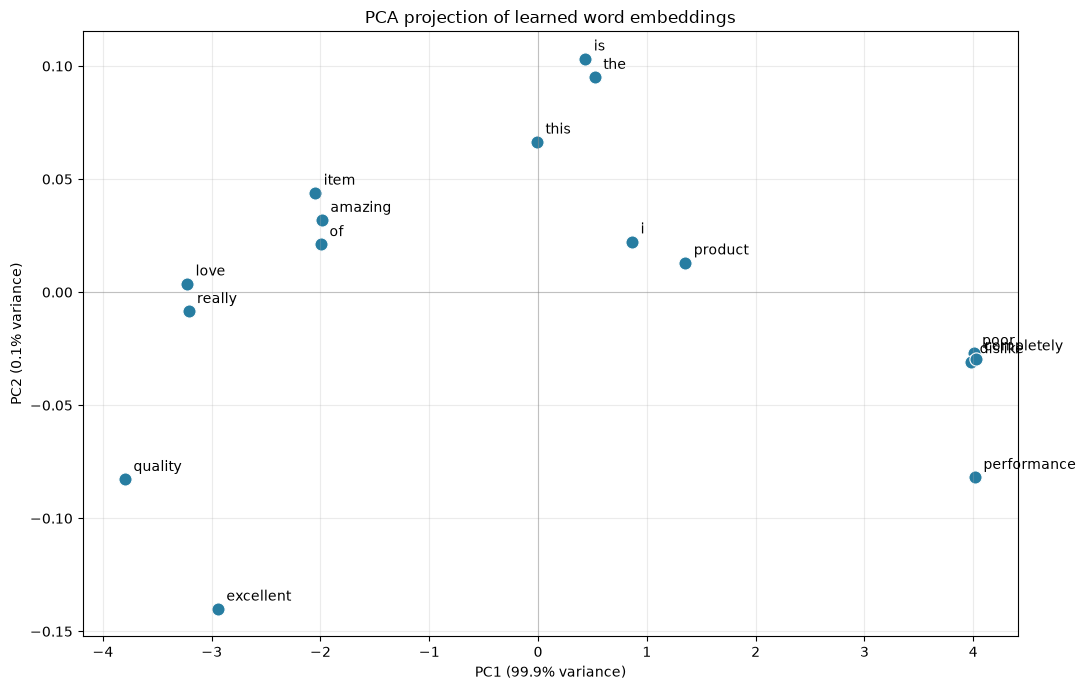

In [11]:
word_vectors_for_pca = embedding_matrix[1:]
pca = PCA(n_components=2, random_state=SEED)
pca_coordinates = pca.fit_transform(word_vectors_for_pca)
pca_df = pd.DataFrame({
    "word": words,
    "PC1": pca_coordinates[:, 0],
    "PC2": pca_coordinates[:, 1],
})
display(pca_df.round(4))
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
assert pca_coordinates.shape == (len(words), 2)

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(pca_df["PC1"], pca_df["PC2"], s=90, color="#277da1", edgecolor="white", linewidth=0.8)
for _, row in pca_df.iterrows():
    ax.annotate(row["word"], (row["PC1"], row["PC2"]), xytext=(6, 6), textcoords="offset points", fontsize=10)
ax.axhline(0, color="gray", linewidth=0.8, alpha=0.4)
ax.axvline(0, color="gray", linewidth=0.8, alpha=0.4)
ax.set(
    title="PCA projection of learned word embeddings",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)",
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Conclusions and limitations

The complete representation pipeline is:

1. Reviews are normalized into consistent lowercase tokens.
2. Each unique word receives a positive vocabulary ID; `0` is reserved for padding.
3. Reviews become variable-length token sequences and then uniform post-padded rows.
4. The Keras embedding layer maps each ID to an eight-dimensional dense vector.
5. Supervised training updates the embedding matrix through the sentiment objective.
6. Each review’s embedding matrix is flattened into a fixed-length feature vector of `max_length × 8` values.
7. PCA projects vocabulary-word vectors into two dimensions for visual inspection.

**Limitations:** This is a five-example teaching dataset, so the learned geometry is unstable and does not establish reliable semantic similarity. The labels are supplied for demonstration, there is no held-out evaluation, and PCA is a variance-preserving projection rather than a direct measure of meaning. A production system would use substantially more data, validation, and usually pretrained or larger contextual embeddings.